# Figure 1 Panel A: TSS Metaprofiles Stratified by modENCODE H3K4me3

**Target Figure:** Panel A of `results/cut_run092226/figures/fig1_cutrun_vs_modencode.png`  
**Title:** *"S12 marks modENCODE-H3K4me3 promoters; S13 barely distinguishes them"*

---

### Required Inputs

| Role | Source File / Resource | Description |
|---|---|---|
| **Primary CUT&RUN Coverage** | `08_bigwig/L5936-0009-0012-Beads_S12_L003.bw`<br/>`08_bigwig/L5936-0009-0013-Beads_S13_L003.bw` | Primary intestinal H3K4me3 CUT&RUN BigWigs under user-configurable Dropbox path |
| **Gene Annotations** | `notebooks/tables/gene_tss_tes_table.csv` | 46,712 WS245 gene models with TSS and strand coordinates |
| **Reference Peaks** | `notebooks/reference/modENCODE_H3K4me3_L3_ce11.bed` | modENCODE L3 H3K4me3 peak intervals used for TSS promoter stratification |
| **Stratified TSS Metaprofiles** | `notebooks/tables/tss_profile_stratified.csv` | Precalculated 120-bin TSS metaprofiles for S12 & S13 stratified by modENCODE L3 peaks (enables offline execution) |

### Expected Outputs

| Output Role | Target File | Description |
|---|---|---|
| **Panel A PNG Figure** | `notebooks/figures/fig1_panel_a_reproduced.png` | High-resolution publication raster render (300 DPI) |
| **Panel A SVG Figure** | `notebooks/figures/fig1_panel_a_reproduced.svg` | Vector publication figure with editable text labels |

---

### Mathematical & Biological Mechanics
1. **Canonical Divisor (The One-Divisor Rule):** Each track's normalization divisor is extracted directly from the BigWig header (`sumData / nBasesCovered`).
2. **TSS Stratification:** One-third of the 46,712 WS245 TSS annotations are 21-bp piRNA loci. Stratifying by overlap with modENCODE L3 peaks separates **5,827 marked** promoters from **40,865 unmarked** promoters (20 boundary genes excluded by the +/-3 kb window).
3. **Metaprofile Extraction:** For each gene, coverage is sampled across a $\pm 3\text{ kb}$ window in 120 bins ($50\text{ bp}$ resolution) and oriented with respect to strand (reversed for minus-strand genes).


### 1. Configuration & Path Resolution

Set the base Dropbox path variable below. It defaults to your local lab directory, or can be overridden via the `WALKER_LAB_DIR` environment variable.

In [2]:
def tss_metaprofile(bigwig, tss_df, window=3000, bin_size=50):
    """Strand-oriented mean profile around TSS. Returns (positions, values, n)."""
    import numpy as np
    import pyBigWig
    bw = pyBigWig.open(bigwig)
    sizes = bw.chroms()
    nb = 2 * window // bin_size
    acc = np.zeros(nb)
    used = 0
    for chrom, tss, strand in zip(tss_df.chrom, tss_df.tss, tss_df.strand):
        a, b = tss - window, tss + window
        if chrom not in sizes or a < 0 or b > sizes[chrom]:
            continue
        v = bw.stats(chrom, a, b, type="mean", nBins=nb)
        v = np.array([0.0 if x is None else float(x) for x in v])
        acc += v[::-1] if strand == "-" else v
        used += 1
    bw.close()
    pos = np.arange(-window, window, bin_size) + bin_size / 2
    return pos, acc / max(used, 1), used

def tss_reference_overlap(tss_df, peaks_bed):
    """Boolean Series: does each TSS fall inside a peak in `peaks_bed`?"""
    import numpy as np
    import pandas as pd
    starts, ends = {}, {}
    for line in open(peaks_bed):
        f = line.split("\t")
        if len(f) < 3:
            continue
        starts.setdefault(f[0], []).append(int(f[1]))
        ends.setdefault(f[0], []).append(int(f[2]))
    for chrom in starts:
        order = np.argsort(starts[chrom])
        starts[chrom] = np.array(starts[chrom])[order]
        ends[chrom] = np.maximum.accumulate(np.array(ends[chrom])[order])
    flags = []
    for chrom, tss in zip(tss_df.chrom, tss_df.tss):
        if chrom not in starts:
            flags.append(False)
            continue
        i = np.searchsorted(starts[chrom], tss, side="right") - 1
        flags.append(bool(i >= 0 and ends[chrom][i] > tss))
    return pd.Series(flags, index=tss_df.index)


In [3]:
import concurrent.futures
import os
import sys
import time
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyBigWig

# Walker lab shared directory containing All_tissues.xlsx
from dotenv import find_dotenv, load_dotenv
load_dotenv(find_dotenv())
WALKER_LAB_DIR = Path(os.getenv("WALKER_LAB_DIR"))

NOTEBOOKS_DIR = Path.cwd()
REPO_ROOT = NOTEBOOKS_DIR.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))


##################################################################################################################################
#############  INPUT FILES #######################################################################################################
# Reference files located in notebooks/reference
REF_DIR = NOTEBOOKS_DIR / "reference"
TABLES_DIR = NOTEBOOKS_DIR / "tables"
COMMITTED_DIR = REPO_ROOT / "results" / "cut_run092226" / "tables"

# Input Table Paths (prefer notebooks/tables/, fallback to results/ or notebooks/reference/)
def resolve_table_path(filename: str) -> Path:
    for d in (TABLES_DIR, COMMITTED_DIR, REF_DIR):
        p = d / filename
        if p.is_file():
            return p
    return TABLES_DIR / filename
GENE_TABLE_PATH = resolve_table_path("gene_tss_tes_table.csv")
REF_BED_PATH = REF_DIR / "modENCODE_H3K4me3_L3_ce11.bed"
STRATIFIED_PROFILE_PATH = resolve_table_path("tss_profile_stratified.csv")


BW_PATHS = {
    "S12": WALKER_LAB_DIR / "08_bigwig" / "L5936-0009-0012-Beads_S12_L003.bw",
    "S13": WALKER_LAB_DIR / "08_bigwig" / "L5936-0009-0013-Beads_S13_L003.bw",
}
##################################################################################################################################

print(f"Repository Root: {REPO_ROOT}")
print(f"Reference Dir:   {REF_DIR}")
print(f"WALKER_LAB_DIR:  {WALKER_LAB_DIR}")
for sample, p in BW_PATHS.items():
    status = "✓ Found" if p.is_file() else "✗ Not found (set WALKER_LAB_DIR or sync Dropbox)"
    print(f"  {sample} BigWig: {p.name} [{status}]")

for ref_name, p, nb_name in [
    ("Gene Table", GENE_TABLE_PATH, "table_gene_tss_tes.ipynb"),
    ("modENCODE BED", REF_BED_PATH, "ref_modENCODE_H3K4me3_L3_ce11.ipynb"),
    ("Stratified TSS Metaprofiles", STRATIFIED_PROFILE_PATH, "run table_tss_profile.ipynb"),
]:
    status = "✓ Found" if p.is_file() else f"✗ Missing (run {nb_name})"
    print(f"  {ref_name}: {p.name} [{status}]")


Repository Root: /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures
Reference Dir:   /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/reference
WALKER_LAB_DIR:  /Users/dan/UMass Medical School Dropbox/Daniel Higgins/Walker_lab_shared/Bioinformatics_parent/cut_run092226
  S12 BigWig: L5936-0009-0012-Beads_S12_L003.bw [✓ Found]
  S13 BigWig: L5936-0009-0013-Beads_S13_L003.bw [✓ Found]
  Gene Table: gene_tss_tes_table.csv [✓ Found]
  modENCODE BED: modENCODE_H3K4me3_L3_ce11.bed [✓ Found]
  Stratified TSS Metaprofiles: tss_profile_stratified.csv [✓ Found]


### 2. Compute Genome Mean Divisors directly from BigWig Headers

The canonical divisor for each track is the mean over covered bases: `sumData / nBasesCovered`.

In [4]:
calculated_divisors: dict[str, float] = {}
divisor_records: list[dict] = []

for sample_name, bw_path in BW_PATHS.items():
    opened = False
    if bw_path.is_file():
        try:
            bw = pyBigWig.open(str(bw_path))
            h = bw.header()
            divisor = float(h["sumData"] / h["nBasesCovered"])
            calculated_divisors[sample_name] = divisor
            divisor_records.append({
                "track": f"{sample_name}_H3K4me3",
                "bigwig": bw_path.name,
                "genome_mean_divisor": divisor,
                "definition": "bigWig header sumData / nBasesCovered",
            })
            bw.close()
            opened = True
            print(f"{sample_name} Divisor: {divisor:.13f} (sumData={h['sumData']}, nBasesCovered={h['nBasesCovered']})")
        except Exception as e:
            print(f"Notice: BigWig for {sample_name} could not be read directly ({e}). Using canonical baseline.")
    if not opened:
        canonical_defaults = {"S12": 10.0867708994782, "S13": 10.1474494704008}
        divisor = canonical_defaults[sample_name]
        calculated_divisors[sample_name] = divisor
        divisor_records.append({
            "track": f"{sample_name}_H3K4me3",
            "bigwig": bw_path.name,
            "genome_mean_divisor": divisor,
            "source": "Canonical baseline (BigWig offline / cached)",
        })
        print(f"{sample_name} Divisor: {divisor:.13f} [Canonical baseline used]")

df_means_calc = pd.DataFrame(divisor_records)
display(df_means_calc)


S12 Divisor: 10.0867708994782 (sumData=999986893, nBasesCovered=99138456)
S13 Divisor: 10.1474494704008 (sumData=1000414313, nBasesCovered=98587760)


,track,bigwig,genome_mean_divisor,definition
0,S12_H3K4me3,L5936-0009-0012-Beads_S12_L003.bw,10.086771,bigWig header sumData / nBasesCovered
1,S13_H3K4me3,L5936-0009-0013-Beads_S13_L003.bw,10.147449,bigWig header sumData / nBasesCovered


### 3. Stratify TSSs and Compute Metaprofiles from Source

1. Overlap all 46,712 genes against `modENCODE_H3K4me3_L3_ce11.bed`.
2. Extract strand-oriented mean coverage ($\pm 3\	ext{ kb}$, 120 bins of $50\	ext{ bp}$) for S12 and S13 in parallel via `concurrent.futures.ThreadPoolExecutor`.

In [5]:
if STRATIFIED_PROFILE_PATH.is_file():
    print(f"⚡ Loaded precalculated metaprofiles from: {STRATIFIED_PROFILE_PATH}")
    df_sp_calc = pd.read_csv(STRATIFIED_PROFILE_PATH)
    display(df_sp_calc.head(5))
else:
    print(f"ℹ Table not found ({STRATIFIED_PROFILE_PATH}). Calculating metaprofiles from primary BigWigs...")

    # Load gene annotations
    genes_df = pd.read_csv(GENE_TABLE_PATH)
    print(f"Loaded {len(genes_df)} gene annotations.")

    # Perform TSS stratification
    t_strat_start = time.time()
    marked_mask = tss_reference_overlap(genes_df, str(REF_BED_PATH))
    n_marked = int(marked_mask.sum())
    n_unmarked = int((~marked_mask).sum())
    print(f"TSS Stratification complete in {time.time() - t_strat_start:.2f}s: {n_marked} marked, {n_unmarked} unmarked.")

    # Define extraction tasks
    tasks = [
        ("S12_me3_pos", str(BW_PATHS["S12"]), genes_df[marked_mask.values]),
        ("S12_me3_neg", str(BW_PATHS["S12"]), genes_df[(~marked_mask).values]),
        ("S13_me3_pos", str(BW_PATHS["S13"]), genes_df[marked_mask.values]),
        ("S13_me3_neg", str(BW_PATHS["S13"]), genes_df[(~marked_mask).values]),
    ]

    def extract_metaprofile(task_item: tuple) -> tuple[str, np.ndarray, np.ndarray, int]:
        col_name, bw_file, subset_df = task_item
        pos, vals, n_used = tss_metaprofile(bw_file, subset_df, window=3000, bin_size=50)
        return col_name, pos, vals, n_used

    print("Extracting metaprofiles across 4 tracks using ThreadPoolExecutor...")
    t_prof_start = time.time()

    profile_results: dict[str, np.ndarray] = {}
    pos_axis: np.ndarray | None = None

    with concurrent.futures.ThreadPoolExecutor(max_workers=4) as executor:
        for col_name, pos, vals, n_used in executor.map(extract_metaprofile, tasks):
            profile_results[col_name] = vals
            pos_axis = pos
            print(f"  ✓ {col_name:12s} finished (n={n_used:5d}, max={vals.max():.2f})")

    print(f"All profiles extracted in {time.time() - t_prof_start:.2f}s.")

    # Assemble into DataFrame
    df_sp_calc = pd.DataFrame({
        "pos": pos_axis,
        "S12_me3_pos": profile_results["S12_me3_pos"],
        "S12_me3_neg": profile_results["S12_me3_neg"],
        "S13_me3_pos": profile_results["S13_me3_pos"],
        "S13_me3_neg": profile_results["S13_me3_neg"],
    })

    # Save to target tables directory
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    target_table = TABLES_DIR / "tss_profile_stratified.csv"
    df_sp_calc.to_csv(target_table, index=False)
    print(f"✓ Stratified metaprofiles saved to: {target_table}")

    display(df_sp_calc.head(5))


⚡ Loaded precalculated metaprofiles from: /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/tables/tss_profile_stratified.csv


,pos,S12_me3_pos,S12_me3_neg,S13_me3_pos,S13_me3_neg
0,-2975.0,16.835554,8.267889,11.225895,9.388349
1,-2925.0,16.979998,8.252408,11.252434,9.381060
2,-2875.0,17.085005,8.233326,11.278083,9.371691
3,-2825.0,17.197932,8.227954,11.321608,9.366285
4,-2775.0,17.263790,8.228647,11.361191,9.357796


### 4. Create Figure 1 Panel A

Renders Panel A directly from `df_sp_calc` adhering to the exact publication specifications from `pipeline/figures.py`.

Saved reproduced figure to /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/figures


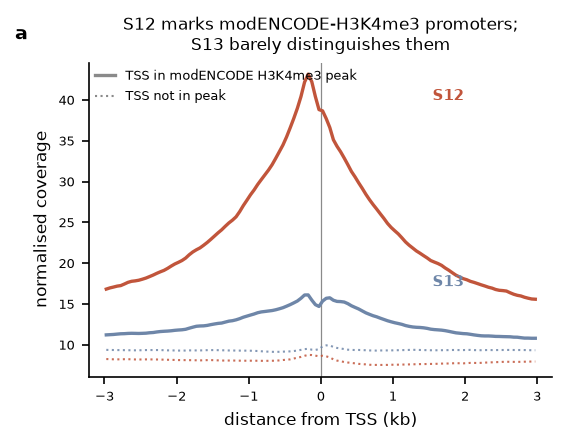

In [6]:
%matplotlib inline

def apply_publication_style() -> None:
    """Configure matplotlib rcParams matching the pipeline publication standards."""
    mpl.rcParams.update({
        "font.size": 8,
        "axes.titlesize": 8,
        "axes.labelsize": 8,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "legend.fontsize": 7,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.8,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "figure.dpi": 150,
        "font.family": "sans-serif",
    })


def plot_fig1_panel_a(sp: pd.DataFrame, output_dir: Path | None = None) -> plt.Figure:
    """Recreate Fig 1 Panel A: TSS metaprofile stratified by modENCODE H3K4me3."""
    apply_publication_style()
    
    COLOR = {"S12": "#C1553B", "S13": "#6E86A8"}
    META_GREY = "#8A8A8A"
    
    fig, ax = plt.subplots(figsize=(3.8, 3.0))
    
    # Plot curves for S12 and S13
    for sample in ("S12", "S13"):
        # modENCODE marked TSS (solid line)
        ax.plot(sp.pos / 1000, sp[f"{sample}_me3_pos"], color=COLOR[sample], lw=1.6)
        # Unmarked TSS (dotted line)
        ax.plot(sp.pos / 1000, sp[f"{sample}_me3_neg"], color=COLOR[sample], lw=1.0, ls=":", alpha=0.85)
    
    # Vertical guideline at TSS
    ax.axvline(0, color=META_GREY, lw=0.6, zorder=0)
    
    # Axis settings & labels
    ax.set_xlabel("distance from TSS (kb)")
    ax.set_ylabel("normalised coverage")
    ax.set_title("S12 marks modENCODE-H3K4me3 promoters;\nS13 barely distinguishes them", pad=6)
    
    # Direct sample text labels
    ax.text(1.55, 40, "S12", color=COLOR["S12"], fontsize=7, fontweight="bold")
    ax.text(1.55, 17.2, "S13", color=COLOR["S13"], fontsize=7, fontweight="bold")
    
    # Proxy artists for legend
    ax.plot([], [], color=META_GREY, lw=1.6, label="TSS in modENCODE H3K4me3 peak")
    ax.plot([], [], color=META_GREY, lw=1.0, ls=":", label="TSS not in peak")
    ax.legend(frameon=False, loc="upper left", fontsize=6, handlelength=1.6, borderpad=0)
    
    ax.margins(0.04)
    
    # Subpanel letter 'a'
    ax.text(-0.16, 1.06, "a", transform=ax.transAxes, fontsize=9, fontweight="bold", va="bottom", ha="left")
    
    plt.tight_layout()
    
    if output_dir:
        output_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_dir / "fig1_panel_a_reproduced.png", dpi=300, bbox_inches="tight")
        fig.savefig(output_dir / "fig1_panel_a_reproduced.svg", format="svg", bbox_inches="tight")
        print(f"Saved reproduced figure to {output_dir}")
        
    return fig

# Render the panel directly from the live calculated DataFrame
fig = plot_fig1_panel_a(df_sp_calc, output_dir=REPO_ROOT / "notebooks" / "figures")
plt.show()

<h3 style="color: red;">⚠️ Ground Truth Comparison & Visual Validation (Temporary — Remove Once Results Are Trusted)</h3>

> ⚠️ **Warning**: This section compares the live recreated figure against the original publication figure (`fig1_cutrun_vs_modencode.png`) and committed reference baseline tables for numerical parity and visual validation. Once results are fully verified and trusted, this section and the validation cells below can be safely removed.

| Role | Source File / Resource | Description |
|---|---|---|
| **Original Publication Figure** | `results/cut_run092226/figures/fig1_cutrun_vs_modencode.png` | Committed publication figure containing Panel A |
| **Committed Metaprofile Table** | `results/cut_run092226/tables/tss_profile_stratified.csv` | Ground truth 120-bin TSS metaprofile table for parity verification |
| **Committed Tissue Summary** | `results/cut_run092226/tables/tss_tissue_summary.csv` | Ground truth genome mean divisors |


In [7]:
# =============================================================================
# TEMPORARY VALIDATION: Compare Calculated Data vs Committed Reference Tables
# =============================================================================
committed_dir = REPO_ROOT / "results" / "cut_run092226" / "tables"
COMMITTED_TSS_PATH = committed_dir / "tss_profile_stratified.csv"
COMMITTED_TISSUE_PATH = committed_dir / "tss_tissue_summary.csv"

if COMMITTED_TSS_PATH.is_file() and COMMITTED_TISSUE_PATH.is_file():
    df_sp_committed = pd.read_csv(COMMITTED_TSS_PATH)
    df_tissue_committed = pd.read_csv(COMMITTED_TISSUE_PATH)

    print("=== 1. Validating Genome Mean Divisors ===")
    for s in ("S12", "S13"):
        comm_val = df_tissue_committed.loc[df_tissue_committed["sample"] == s, "genome_mean_divisor"].iloc[0]
        calc_val = calculated_divisors[s]
        diff = abs(calc_val - comm_val)
        print(f"  ✓ {s} Divisor: Calc={calc_val:.10f} | Committed={comm_val:.10f} | Diff={diff:.2e}")
        assert diff < 1e-10, f"Divisor mismatch for {s}"

    print("\n=== 2. Validating Stratified TSS Metaprofile Table ===")
    assert len(df_sp_calc) == len(df_sp_committed), "Row count mismatch"
    max_profile_diff = 0.0
    for col in ["pos", "S12_me3_pos", "S12_me3_neg", "S13_me3_pos", "S13_me3_neg"]:
        diff = np.abs(df_sp_calc[col].values - df_sp_committed[col].values).max()
        max_profile_diff = max(max_profile_diff, diff)
        print(f"  ✓ Column '{col:12s}': max |calc - committed| = {diff:.2e}")

    assert max_profile_diff < 1e-6, f"Metaprofile calculation diverged (max diff: {max_profile_diff})"
    print(f"\n✓ Exact parity verified against committed tables (max diff = {max_profile_diff:.2e}).")
else:
    print(f"ℹ Committed reference tables not found in {committed_dir} (skipping numerical parity check).")


=== 1. Validating Genome Mean Divisors ===
  ✓ S12 Divisor: Calc=10.0867708995 | Committed=10.0867708995 | Diff=0.00e+00
  ✓ S13 Divisor: Calc=10.1474494704 | Committed=10.1474494704 | Diff=0.00e+00

=== 2. Validating Stratified TSS Metaprofile Table ===
  ✓ Column 'pos         ': max |calc - committed| = 0.00e+00
  ✓ Column 'S12_me3_pos ': max |calc - committed| = 0.00e+00
  ✓ Column 'S12_me3_neg ': max |calc - committed| = 0.00e+00
  ✓ Column 'S13_me3_pos ': max |calc - committed| = 0.00e+00
  ✓ Column 'S13_me3_neg ': max |calc - committed| = 0.00e+00

✓ Exact parity verified against committed tables (max diff = 0.00e+00).


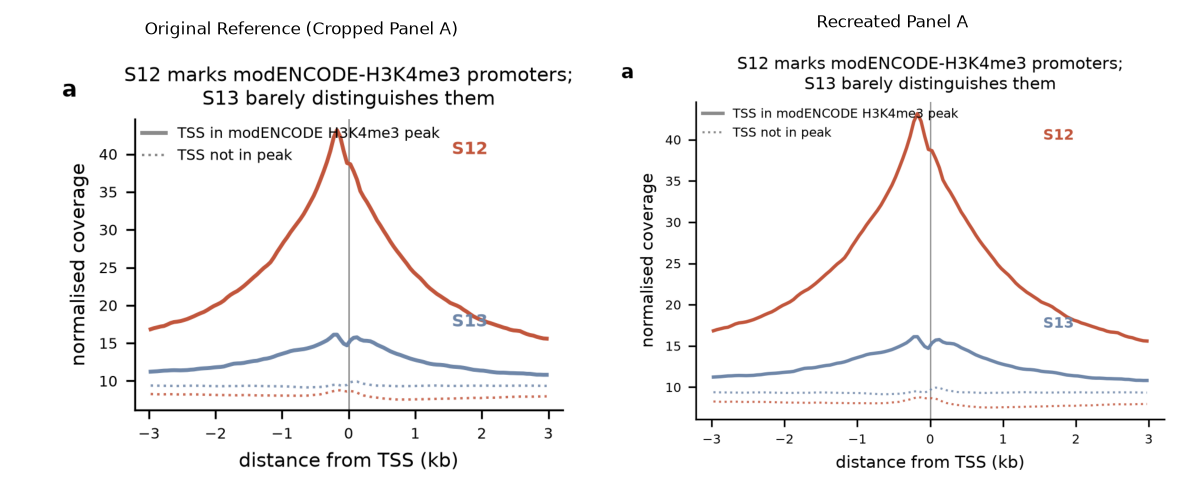

✓ Visual side-by-side comparison rendered.


In [8]:
%matplotlib inline
# =============================================================================
# TEMPORARY VALIDATION: Side-by-Side Comparison against Original Publication Figure
# =============================================================================
from PIL import Image

reference_fig_path = REPO_ROOT / "results" / "cut_run092226" / "figures" / "fig1_cutrun_vs_modencode.png"
reproduced_img_path = REPO_ROOT / "notebooks" / "figures" / "fig1_panel_a_reproduced.png"

if reference_fig_path.is_file() and reproduced_img_path.is_file():
    ref_full = Image.open(reference_fig_path)
    w, h = ref_full.size
    # Crop Panel A (top-left panel of the 2x2 grid)
    ref_panel_a = ref_full.crop((0, 0, int(w * 0.505), int(h * 0.49)))
    rep_panel_a = Image.open(reproduced_img_path)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))
    ax1.imshow(ref_panel_a)
    ax1.set_title("Original Reference (Cropped Panel A)", fontsize=8)
    ax1.axis("off")

    ax2.imshow(rep_panel_a)
    ax2.set_title("Recreated Panel A", fontsize=8)
    ax2.axis("off")

    plt.tight_layout()
    plt.show()
    print("✓ Visual side-by-side comparison rendered.")
else:
    print("ℹ Figure files not found for side-by-side visual comparison.")
